In [2]:
!pip install -q transformers accelerate

import copy
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from transformers import AutoImageProcessor, AutoModelForImageClassification
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report as cr,
                             confusion_matrix as cm_fn, roc_auc_score, roc_curve)

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
dataset_path = "/content/drive/MyDrive/Vitiligo DS"

for folder in os.listdir(dataset_path):
    full = os.path.join(dataset_path, folder)
    if os.path.isdir(full):
        n = sum(f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')) for f in os.listdir(full))
        print(f"{folder}: {n} images")

Healthy Skin: 891 images
vitiligo: 380 images


In [4]:
model_name = "google/vit-base-patch16-224"

processor = AutoImageProcessor.from_pretrained(model_name)

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(processor.image_mean, processor.image_std)
])

test_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(processor.image_mean, processor.image_std)
])

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

In [5]:
# Two copies: one with augmentation (train), one without (val/test)
full_train = datasets.ImageFolder(dataset_path, transform=train_tf)
full_test = datasets.ImageFolder(dataset_path, transform=test_tf)

class_names = full_train.classes
targets = full_train.targets
print("Classes:", class_names)
print("Total images:", len(full_train))
print("Per class:", {class_names[i]: targets.count(i) for i in range(len(class_names))})

train_idx, temp_idx = train_test_split(
    list(range(len(targets))), test_size=0.30, stratify=targets, random_state=42)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=[targets[i] for i in temp_idx], random_state=42)

train_data = Subset(full_train, train_idx)
val_data = Subset(full_test, val_idx)
test_data = Subset(full_test, test_idx)

print("Train:", len(train_data), "Val:", len(val_data), "Test:", len(test_data))

Classes: ['Healthy Skin', 'vitiligo']
Total images: 1271
Per class: {'Healthy Skin': 891, 'vitiligo': 380}
Train: 889 Val: 191 Test: 191


In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 16

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

print("Device:", device)

Device: cuda


In [7]:
id2label = {i: n for i, n in enumerate(class_names)}
label2id = {n: i for i, n in enumerate(class_names)}

model = AutoModelForImageClassification.from_pretrained(
    model_name,
    num_labels=len(class_names),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
).to(device)

print(model.config.id2label)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


{0: 'Healthy Skin', 1: 'vitiligo'}


In [8]:
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
epochs = 5

def run_eval(loader):
    model.eval()
    total_loss, labels_all, preds_all, probs_all = 0, [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(pixel_values=images).logits
            total_loss += criterion(logits, labels).item() * images.size(0)
            labels_all += labels.cpu().tolist()
            preds_all += logits.argmax(dim=1).cpu().tolist()
            probs_all += torch.softmax(logits, dim=1).cpu().tolist()
    return total_loss / len(labels_all), accuracy_score(labels_all, preds_all), labels_all, preds_all, np.array(probs_all)

In [9]:
train_losses, train_accs, val_losses, val_accs = [], [], [], []
best_acc, best_state = 0, None

for epoch in range(epochs):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(pixel_values=images).logits
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += images.size(0)

    train_loss, train_acc = total_loss / total, correct / total
    val_loss, val_acc, _, _, _ = run_eval(val_loader)

    train_losses.append(train_loss); train_accs.append(train_acc)
    val_losses.append(val_loss); val_accs.append(val_acc)

    if val_acc > best_acc:
        best_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch+1}/{epochs} | Train Loss {train_loss:.4f} Acc {train_acc:.4f} | Val Loss {val_loss:.4f} Acc {val_acc:.4f}")

model.load_state_dict(best_state)
print("Best validation accuracy:", best_acc)

Epoch 1/5 | Train Loss 0.1507 Acc 0.9246 | Val Loss 0.0592 Acc 0.9895
Epoch 2/5 | Train Loss 0.0135 Acc 0.9989 | Val Loss 0.0272 Acc 1.0000
Epoch 3/5 | Train Loss 0.0056 Acc 1.0000 | Val Loss 0.0205 Acc 1.0000
Epoch 4/5 | Train Loss 0.0027 Acc 1.0000 | Val Loss 0.0176 Acc 1.0000
Epoch 5/5 | Train Loss 0.0015 Acc 1.0000 | Val Loss 0.0155 Acc 1.0000
Best validation accuracy: 1.0


In [10]:
test_loss, test_acc, y_true, y_pred, y_prob = run_eval(test_loader)
print("Test Accuracy:", test_acc)
print(cr(y_true, y_pred, target_names=class_names))

auc = roc_auc_score(y_true, y_prob[:, 1])
print(f"ROC-AUC: {auc:.4f}")

Test Accuracy: 1.0
              precision    recall  f1-score   support

Healthy Skin       1.00      1.00      1.00       134
    vitiligo       1.00      1.00      1.00        57

    accuracy                           1.00       191
   macro avg       1.00      1.00      1.00       191
weighted avg       1.00      1.00      1.00       191

ROC-AUC: 1.0000


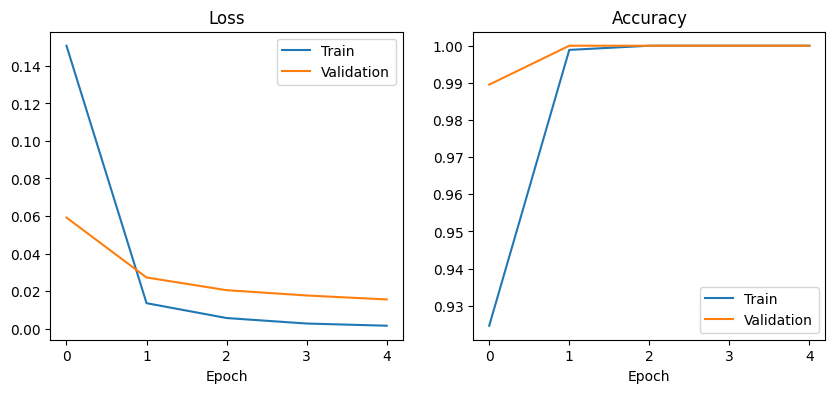

In [11]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label="Train")
plt.plot(val_accs, label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.show()

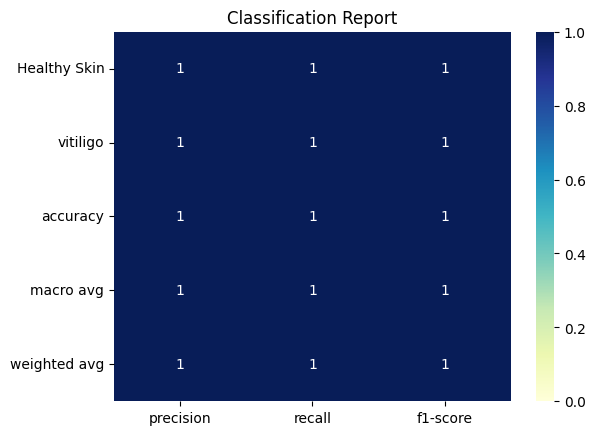

In [12]:
report = cr(y_true, y_pred, target_names=class_names, output_dict=True)
scores = pd.DataFrame(report).T[["precision", "recall", "f1-score"]]

sns.heatmap(scores, annot=True, cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Classification Report")
plt.show()

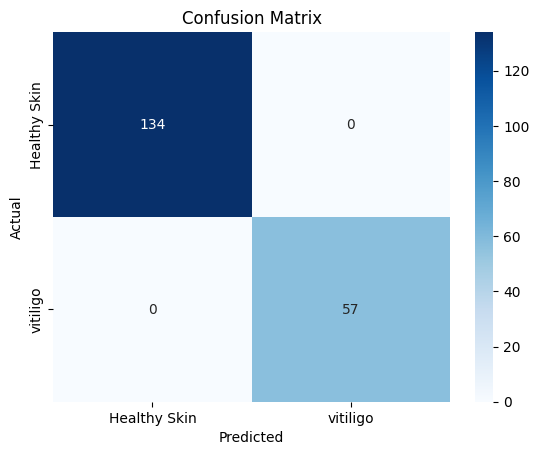

In [13]:
cm = cm_fn(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [14]:
save_path = "/content/drive/MyDrive/vitiligo_vit_model"
model.save_pretrained(save_path)
processor.save_pretrained(save_path)
print("Saved at", save_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved at /content/drive/MyDrive/vitiligo_vit_model


In [17]:
def predict(image_path):
    img = Image.open(image_path).convert("RGB")
    x = test_tf(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(pixel_values=x).logits, dim=1)[0]
    i = probs.argmax().item()
    plt.imshow(img); plt.axis("off")
    plt.title(f"{class_names[i]} ({probs[i]:.1%})")
    plt.show()

# Example usage:
# predict("/content/drive/MyDrive/Vitiligo DS/vitiligo/roi0.jpg")

In [18]:
import os
app_dir = "/content/drive/MyDrive/vitiligo_app"
model_dir = "/content/drive/MyDrive/vitiligo_vit_model"

print("main.py:", os.path.exists(f"{app_dir}/main.py"))
print("index.html:", os.path.exists(f"{app_dir}/static/index.html"))
print("model files:", os.listdir(model_dir))

main.py: False
index.html: False
model files: ['config.json', 'model.safetensors', 'preprocessor_config.json']


In [21]:
import os, shutil
from google.colab import files

os.makedirs("/content/vitiligo_app/static", exist_ok=True)
uploaded = files.upload()

for name in uploaded:
    dest = "/content/vitiligo_app/static/index.html" if name.startswith("index") else f"/content/vitiligo_app/{name}"
    shutil.move(name, dest)

print("main.py:", os.path.exists("/content/vitiligo_app/main.py"))
print("index.html:", os.path.exists("/content/vitiligo_app/static/index.html"))
print("model files:", os.listdir("/content/drive/MyDrive/vitiligo_vit_model"))

Saving index.html to index.html
main.py: True
index.html: True
model files: ['config.json', 'model.safetensors', 'preprocessor_config.json']


In [23]:
!pip install -q fastapi "uvicorn[standard]" python-multipart
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /usr/local/bin/cloudflared
!chmod +x /usr/local/bin/cloudflared

In [27]:
HTML = r"""<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>DermaScan AI · Vitiligo Detector</title>
<link rel="icon" href="data:image/svg+xml,<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 100 100'><text y='.9em' font-size='90'>🔬</text></svg>">
<link href="https://fonts.googleapis.com/css2?family=Poppins:wght@400;500;600;700&display=swap" rel="stylesheet">
<style>
  :root{
    --bg:#0b1020; --card:rgba(255,255,255,.06); --border:rgba(255,255,255,.12);
    --text:#eef1ff; --muted:#9aa4c7; --a:#7c5cff; --b:#00d4ff;
    --ok:#2ee59d; --warn:#ff5c7a;
  }
  *{box-sizing:border-box;margin:0;padding:0}
  body{
    font-family:'Poppins',system-ui,sans-serif;color:var(--text);min-height:100vh;
    background:radial-gradient(circle at 15% 20%,#2a1b6e 0,transparent 40%),
               radial-gradient(circle at 85% 80%,#07506b 0,transparent 40%),var(--bg);
    display:flex;flex-direction:column;align-items:center;padding:32px 16px;overflow-x:hidden;
  }
  .blob{position:fixed;border-radius:50%;filter:blur(80px);opacity:.35;z-index:-1;animation:float 12s ease-in-out infinite}
  .blob.one{width:320px;height:320px;background:var(--a);top:-80px;left:-80px}
  .blob.two{width:280px;height:280px;background:var(--b);bottom:-80px;right:-60px;animation-delay:-6s}
  @keyframes float{50%{transform:translate(40px,30px) scale(1.1)}}

  header{text-align:center;margin-bottom:28px}
  .logo{font-size:44px;display:inline-block;animation:pulse 3s infinite}
  @keyframes pulse{50%{transform:scale(1.12)}}
  h1{font-size:clamp(28px,5vw,42px);font-weight:700;
     background:linear-gradient(90deg,var(--a),var(--b));-webkit-background-clip:text;background-clip:text;color:transparent}
  header p{color:var(--muted);margin-top:6px;font-size:15px}
  .badges{display:flex;gap:8px;justify-content:center;margin-top:14px;flex-wrap:wrap}
  .badge{font-size:12px;padding:5px 12px;border:1px solid var(--border);border-radius:99px;background:var(--card);color:var(--muted)}

  .card{
    width:100%;max-width:760px;background:var(--card);border:1px solid var(--border);
    border-radius:24px;padding:28px;backdrop-filter:blur(16px);box-shadow:0 20px 60px rgba(0,0,0,.4);
  }
  .drop{
    display:block;border:2px dashed var(--border);border-radius:18px;padding:36px 20px;text-align:center;
    cursor:pointer;transition:.25s;position:relative;
  }
  .drop:hover,.drop.drag{border-color:var(--b);background:rgba(0,212,255,.07);transform:translateY(-2px)}
  .drop .icon{font-size:46px}
  .drop h3{margin:10px 0 4px;font-weight:600}
  .drop p{color:var(--muted);font-size:13px}
  input[type=file]{display:none}

  .btn{
    border:0;border-radius:14px;padding:13px 26px;font:600 15px 'Poppins',sans-serif;cursor:pointer;color:#fff;
    background:linear-gradient(135deg,var(--a),var(--b));transition:.25s;
    box-shadow:0 8px 24px rgba(124,92,255,.4);
  }
  .btn:hover:not(:disabled){transform:translateY(-2px);box-shadow:0 12px 30px rgba(0,212,255,.45)}
  .btn:disabled{opacity:.45;cursor:not-allowed;box-shadow:none}
  .btn.ghost{background:transparent;border:1px solid var(--border);box-shadow:none;color:var(--text)}
  .btn.ghost:hover:not(:disabled){border-color:var(--warn);color:var(--warn);box-shadow:none}
  .actions{display:flex;gap:12px;justify-content:center;margin-top:22px;flex-wrap:wrap}

  .preview{display:none;margin-top:22px;animation:rise .5s ease}
  @keyframes rise{from{opacity:0;transform:translateY(14px)}}
  .imgwrap{position:relative;border-radius:18px;overflow:hidden;border:1px solid var(--border);max-height:380px;display:flex;justify-content:center;background:#000}
  .imgwrap img{max-width:100%;max-height:380px;object-fit:contain;display:block}
  .scan{display:none;position:absolute;left:0;right:0;height:3px;background:linear-gradient(90deg,transparent,var(--b),transparent);
        box-shadow:0 0 20px 6px var(--b);animation:scan 1.6s linear infinite}
  .imgwrap.scanning .scan{display:block}
  .imgwrap.scanning img{filter:brightness(.75)}
  @keyframes scan{from{top:0}to{top:100%}}
  .meta{display:flex;justify-content:space-between;gap:10px;margin-top:10px;font-size:12px;color:var(--muted);flex-wrap:wrap}

  .result{display:none;margin-top:24px;padding:22px;border-radius:18px;border:1px solid var(--border);background:rgba(0,0,0,.25);animation:rise .5s ease}
  .verdict{display:flex;align-items:center;gap:14px}
  .verdict .emoji{font-size:40px}
  .verdict h2{font-size:22px}
  .verdict small{color:var(--muted)}
  .tag{display:inline-block;font-size:11px;padding:3px 10px;border-radius:99px;margin-left:8px;vertical-align:middle;font-weight:600}
  .tag.pos{background:rgba(255,92,122,.18);color:var(--warn)}
  .tag.neg{background:rgba(46,229,157,.18);color:var(--ok)}
  .bars{margin-top:18px;display:grid;gap:12px}
  .bar-row .top{display:flex;justify-content:space-between;font-size:13px;margin-bottom:5px}
  .track{height:10px;border-radius:99px;background:rgba(255,255,255,.08);overflow:hidden}
  .fill{height:100%;width:0;border-radius:99px;transition:width 1s cubic-bezier(.2,.8,.2,1)}
  .fill.pos{background:linear-gradient(90deg,#ff8a5c,var(--warn))}
  .fill.neg{background:linear-gradient(90deg,#1fbf8a,var(--ok))}
  .note{margin-top:14px;font-size:12px;color:#ffd166;display:none}

  .disclaimer{max-width:760px;margin-top:22px;text-align:center;font-size:12px;color:var(--muted);line-height:1.6}
  .tips{display:grid;grid-template-columns:repeat(auto-fit,minmax(150px,1fr));gap:10px;width:100%;max-width:760px;margin-top:22px}
  .tip{background:var(--card);border:1px solid var(--border);border-radius:14px;padding:12px;font-size:12px;color:var(--muted);text-align:center}
  .tip b{display:block;font-size:20px;margin-bottom:4px}

  .spinner{display:inline-block;width:14px;height:14px;border:2px solid rgba(255,255,255,.4);border-top-color:#fff;border-radius:50%;animation:spin .7s linear infinite;vertical-align:-2px;margin-right:8px}
  @keyframes spin{to{transform:rotate(360deg)}}
  #toast{position:fixed;bottom:24px;left:50%;transform:translate(-50%,120px);background:#2b1230;border:1px solid var(--warn);color:#ffd6de;
         padding:12px 20px;border-radius:12px;font-size:14px;transition:.4s;z-index:10;max-width:90%}
  #toast.show{transform:translate(-50%,0)}
  footer{margin-top:26px;color:var(--muted);font-size:12px}
</style>
</head>
<body>
<div class="blob one"></div><div class="blob two"></div>

<header>
  <div class="logo"></div>
  <h1>DermaScan AI</h1>
  <p>Vitiligo detection from skin images using a Vision Transformer</p>
  <div class="badges">
    <span class="badge"> ViT-Base / 16</span>
    <span class="badge"> FastAPI</span>
    <span class="badge">Images are not stored</span>
  </div>
</header>

<main class="card">
  <label class="drop" id="drop" for="fileInput">
    <div class="icon"></div>
    <h3>Click to upload or drag &amp; drop</h3>
    <p>JPG, PNG, WEBP or BMP · max 10 MB</p>
  </label>
  <input type="file" id="fileInput" accept="image/*">

  <div class="preview" id="preview">
    <div class="imgwrap" id="imgwrap">
      <img id="previewImg" alt="Selected skin image">
      <div class="scan"></div>
    </div>
    <div class="meta"><span id="fname"></span><span id="fsize"></span><span id="fdim"></span></div>
  </div>

  <div class="actions">
    <button class="btn" id="analyzeBtn" disabled> Analyze Image</button>
    <button class="btn ghost" id="resetBtn" style="display:none">✖ Clear</button>
  </div>

  <section class="result" id="result">
    <div class="verdict">
      <div class="emoji" id="emoji"></div>
      <div>
        <h2><span id="label"></span><span class="tag" id="tag"></span></h2>
        <small id="confText"></small>
      </div>
    </div>
    <div class="bars" id="bars"></div>
    <div class="note" id="note"> Low confidence. Try a clearer, well-lit, close-up photo of the skin area.</div>
  </section>
</main>

<div class="tips">
  <div class="tip"><b></b>Use good natural lighting</div>
  <div class="tip"><b></b>Keep the skin area in focus</div>
  <div class="tip"><b></b>Fill the frame with the area</div>
  <div class="tip"><b></b>Avoid filters &amp; heavy edits</div>
</div>

<p class="disclaimer">
  This tool is a student machine-learning project and is <strong>not a medical diagnosis</strong>.
  The model only knows two classes (healthy skin vs. vitiligo), so it may give a confident answer even for unrelated images.
  Please consult a dermatologist for any skin concern.
</p>
<footer>Built by Ali Jaffar · FAST-NUCES · Powered by PyTorch &amp; Hugging Face</footer>
<div id="toast"></div>

<script>
const $ = id => document.getElementById(id);
const fileInput=$('fileInput'), drop=$('drop'), analyzeBtn=$('analyzeBtn'), resetBtn=$('resetBtn');
let currentFile=null;

function toast(msg){const t=$('toast');t.textContent=msg;t.classList.add('show');setTimeout(()=>t.classList.remove('show'),3500)}
function fmtSize(b){return b>1048576?(b/1048576).toFixed(2)+' MB':(b/1024).toFixed(1)+' KB'}

function handleFile(file){
  if(!file) return;
  if(!file.type.startsWith('image/')) return toast('Please choose an image file.');
  if(file.size>10*1024*1024) return toast('File is too large (max 10 MB).');
  currentFile=file;
  const url=URL.createObjectURL(file);
  const img=$('previewImg');
  img.onload=()=>{$('fdim').textContent=` ${img.naturalWidth}×${img.naturalHeight}px`};
  img.src=url;
  $('fname').textContent=' '+(file.name.length>28?file.name.slice(0,25)+'…':file.name);
  $('fsize').textContent=' '+fmtSize(file.size);
  $('preview').style.display='block';
  $('result').style.display='none';
  analyzeBtn.disabled=false; resetBtn.style.display='inline-block';
  drop.querySelector('h3').textContent='Choose a different image';
}

fileInput.addEventListener('change',e=>handleFile(e.target.files[0]));
['dragenter','dragover'].forEach(ev=>drop.addEventListener(ev,e=>{e.preventDefault();drop.classList.add('drag')}));
['dragleave','drop'].forEach(ev=>drop.addEventListener(ev,e=>{e.preventDefault();drop.classList.remove('drag')}));
drop.addEventListener('drop',e=>handleFile(e.dataTransfer.files[0]));

resetBtn.addEventListener('click',()=>{
  currentFile=null; fileInput.value='';
  $('preview').style.display='none'; $('result').style.display='none';
  analyzeBtn.disabled=true; resetBtn.style.display='none';
  drop.querySelector('h3').textContent='Click to upload or drag & drop';
});

analyzeBtn.addEventListener('click',async()=>{
  if(!currentFile) return;
  analyzeBtn.disabled=true;
  analyzeBtn.innerHTML='<span class="spinner"></span>Analyzing…';
  $('imgwrap').classList.add('scanning'); $('result').style.display='none';
  const fd=new FormData(); fd.append('file',currentFile);
  try{
    const [res]=await Promise.all([fetch('/predict',{method:'POST',body:fd}), new Promise(r=>setTimeout(r,900))]);
    const data=await res.json();
    if(!res.ok) throw new Error(data.detail||'Prediction failed');
    showResult(data);
  }catch(err){ toast(' '+err.message); }
  finally{
    $('imgwrap').classList.remove('scanning');
    analyzeBtn.disabled=false; analyzeBtn.innerHTML='🔍 Analyze Again';
  }
});

const isPos = l => l.toLowerCase().includes('vitiligo');

function showResult(d){
  const pos=isPos(d.prediction);
  $('emoji').textContent=pos?'':'';
  $('label').textContent=d.prediction;
  const tag=$('tag'); tag.textContent=pos?'Vitiligo pattern':'No vitiligo pattern'; tag.className='tag '+(pos?'pos':'neg');
  $('confText').textContent=`Confidence: ${(d.confidence*100).toFixed(1)}%`;
  $('bars').innerHTML=d.probabilities.map(p=>`
    <div class="bar-row">
      <div class="top"><span>${p.label}</span><span>${(p.probability*100).toFixed(1)}%</span></div>
      <div class="track"><div class="fill ${isPos(p.label)?'pos':'neg'}" data-w="${(p.probability*100).toFixed(1)}"></div></div>
    </div>`).join('');
  $('note').style.display=d.confidence<0.7?'block':'none';
  $('result').style.display='block';
  requestAnimationFrame(()=>requestAnimationFrame(()=>
    document.querySelectorAll('.fill').forEach(f=>f.style.width=f.dataset.w+'%')));
  $('result').scrollIntoView({behavior:'smooth',block:'center'});
}
</script>
</body>
</html>"""
print("HTML ready:", len(HTML), "characters")

HTML ready: 12199 characters


In [28]:
import io
import torch
from fastapi import FastAPI, File, HTTPException, UploadFile
from fastapi.responses import HTMLResponse
from PIL import Image, UnidentifiedImageError

MAX_FILE_MB = 10
ALLOWED_TYPES = {"image/jpeg", "image/png", "image/webp", "image/bmp"}

app = FastAPI(title="Vitiligo ViT Classifier")


@app.get("/", response_class=HTMLResponse)
def index():
    return HTML


@app.get("/health")
def health():
    return {"status": "ok", "device": str(device), "classes": class_names}


@app.post("/predict")
async def predict_api(file: UploadFile = File(...)):
    if file.content_type not in ALLOWED_TYPES:
        raise HTTPException(400, "Please upload a JPG, PNG, WEBP or BMP image.")

    data = await file.read()
    if len(data) > MAX_FILE_MB * 1024 * 1024:
        raise HTTPException(400, f"File too large (max {MAX_FILE_MB} MB).")

    try:
        img = Image.open(io.BytesIO(data)).convert("RGB")
    except (UnidentifiedImageError, OSError):
        raise HTTPException(400, "Could not read that image file.")

    # Same preprocessing as the notebook (test_tf)
    x = test_tf(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(pixel_values=x).logits, dim=1)[0].cpu().tolist()

    results = sorted(
        [{"label": class_names[i], "probability": p} for i, p in enumerate(probs)],
        key=lambda r: r["probability"], reverse=True)
    return {
        "prediction": results[0]["label"],
        "confidence": results[0]["probability"],
        "probabilities": results,
        "width": img.width,
        "height": img.height,
    }

print("FastAPI app defined")

FastAPI app defined


In [29]:
import threading, subprocess, re, time, requests, uvicorn

# Start FastAPI in a background thread
config = uvicorn.Config(app, host="0.0.0.0", port=8000, log_level="warning")
server = uvicorn.Server(config)
threading.Thread(target=server.run, daemon=True).start()

for _ in range(20):
    try:
        print("Server ready:", requests.get("http://localhost:8000/health").json())
        break
    except Exception:
        time.sleep(1)

# Public tunnel
tunnel = subprocess.Popen(
    ["cloudflared", "tunnel", "--url", "http://localhost:8000"],
    stderr=subprocess.PIPE, text=True)

for line in tunnel.stderr:
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
    if m:
        print("\n🔗 Open your app here:", m.group(0))
        break

Server ready: {'status': 'ok', 'device': 'cuda', 'classes': ['Healthy Skin', 'vitiligo']}

🔗 Open your app here: https://garden-with-peaceful-endorsed.trycloudflare.com
